In [1]:
from typing import TypedDict


class State(TypedDict):
    customer_name: str
    my_age: int

In [2]:
def node_1(state: State) -> State:
    return state

def node_2(state: State) -> State:
    return state

def node_3(state: State) -> State:
    return state

def node_4(state: State) -> State:
    return state

def node_5(state: State) -> State:
    return state


In [3]:
import random
from typing import Literal


def route_edge(state:State)-> Literal["node_2","node_3","node_4","node_5"]:
    variable=random.random()
    if variable< 0.5:
        return 'node_2'
    elif variable<0.7:
        return 'node_3'    
    elif variable<0.8:
        return 'node_4'
    return 'node_5'

In [6]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)

builder.add_edge(START, "node_1")
builder.add_conditional_edges('node_1',route_edge)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)

agent = builder.compile()

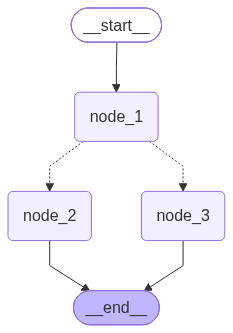

In [7]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

In [4]:
from langgraph.graph import StateGraph, START, END

builder = StateGraph(State)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)
builder.add_node("node_4", node_3)
builder.add_node("node_5", node_3)

builder.add_conditional_edges(START,route_edge)
builder.add_edge("node_2", END)
builder.add_edge("node_3", END)
builder.add_edge("node_4", END)
builder.add_edge("node_5", END)

agent = builder.compile()

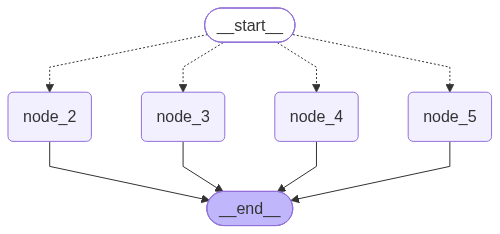

In [5]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))